# Chapter 1: Simulating spin measurements

In chapter 1 of *Quantum Computing for Everyone*, the book describes three rules for measuring electron spin. This notebook turns those rules into code, so I can see the results instead of just reading them.

**The rules (from the chapter):**
1. A measurement gives one of two answers: **N** or **S**, along the direction I choose.
2. Measuring the **same direction** again gives the **same** answer.
3. Measuring a **different direction** (vertical then horizontal) gives a **random 50/50** answer.

I only use two directions here: vertical (0°) and horizontal (90°). Other angles come in chapter 3 once I have the linear algebra.

## 1. The electron model

An electron remembers one thing: the **last direction measured** and the **answer it gave**.

- If I measure in the same direction as last time, I return the stored answer.
- If I measure in a different direction, the old answer is forgotten and the new answer is a coin flip.

This is not how nature works inside. It just reproduces the rules above.

In [1]:
import random
import matplotlib.pyplot as plt

VERTICAL, HORIZONTAL = 0, 90   # directions in degrees, clockwise from up


class Electron:
    def __init__(self):
        self.direction = None   # last direction measured
        self.result = None      # 'N' or 'S'

    def measure(self, direction):
        if direction == self.direction:
            return self.result                      # rule 2: repeat -> same answer
        self.direction = direction                  # rule 3: new direction -> random
        self.result = random.choice(['N', 'S'])
        return self.result

## 2. Experiment 1: same direction twice

Measure vertically, then measure vertically again. The two answers should always match.

In [2]:
random.seed(1)
trials = 10_000
matches = 0
for _ in range(trials):
    e = Electron()
    first = e.measure(VERTICAL)
    second = e.measure(VERTICAL)
    matches += (first == second)

print(f"Same answer both times: {matches} out of {trials}")

Same answer both times: 10000 out of 10000


## 3. Experiment 2: vertical, then horizontal

Keep only electrons that gave **N** vertically. Then measure them horizontally. The book says exactly half should give N and half S.

In [3]:
random.seed(2)
counts = {'N': 0, 'S': 0}
for _ in range(100_000):
    e = Electron()
    if e.measure(VERTICAL) == 'N':
        counts[e.measure(HORIZONTAL)] += 1

total = sum(counts.values())
print(counts)
print(f"N: {counts['N']/total:.3f}   S: {counts['S']/total:.3f}")

{'N': 24695, 'S': 25059}
N: 0.496   S: 0.504


## 4. Experiment 3: vertical, horizontal, vertical

This is the surprising one. Keep electrons that gave **N** vertically, then **N** horizontally. Measure vertically again.

If the electron "kept" its first answer, the last result would always be N. The book says it is 50/50.

In [4]:
random.seed(3)
counts = {'N': 0, 'S': 0}
for _ in range(100_000):
    e = Electron()
    if e.measure(VERTICAL) != 'N':
        continue
    if e.measure(HORIZONTAL) != 'N':
        continue
    counts[e.measure(VERTICAL)] += 1

total = sum(counts.values())
print(counts)
print(f"Third measurement -> N: {counts['N']/total:.3f}   S: {counts['S']/total:.3f}")

{'N': 12482, 'S': 12405}
Third measurement -> N: 0.502   S: 0.498


## 5. Following 100,000 electrons through all three steps

Each step keeps about half: roughly 100,000 -> 50,000 -> 25,000 -> 12,500. This is the same halving as the worked example in my notes (100 -> 50 -> 25).

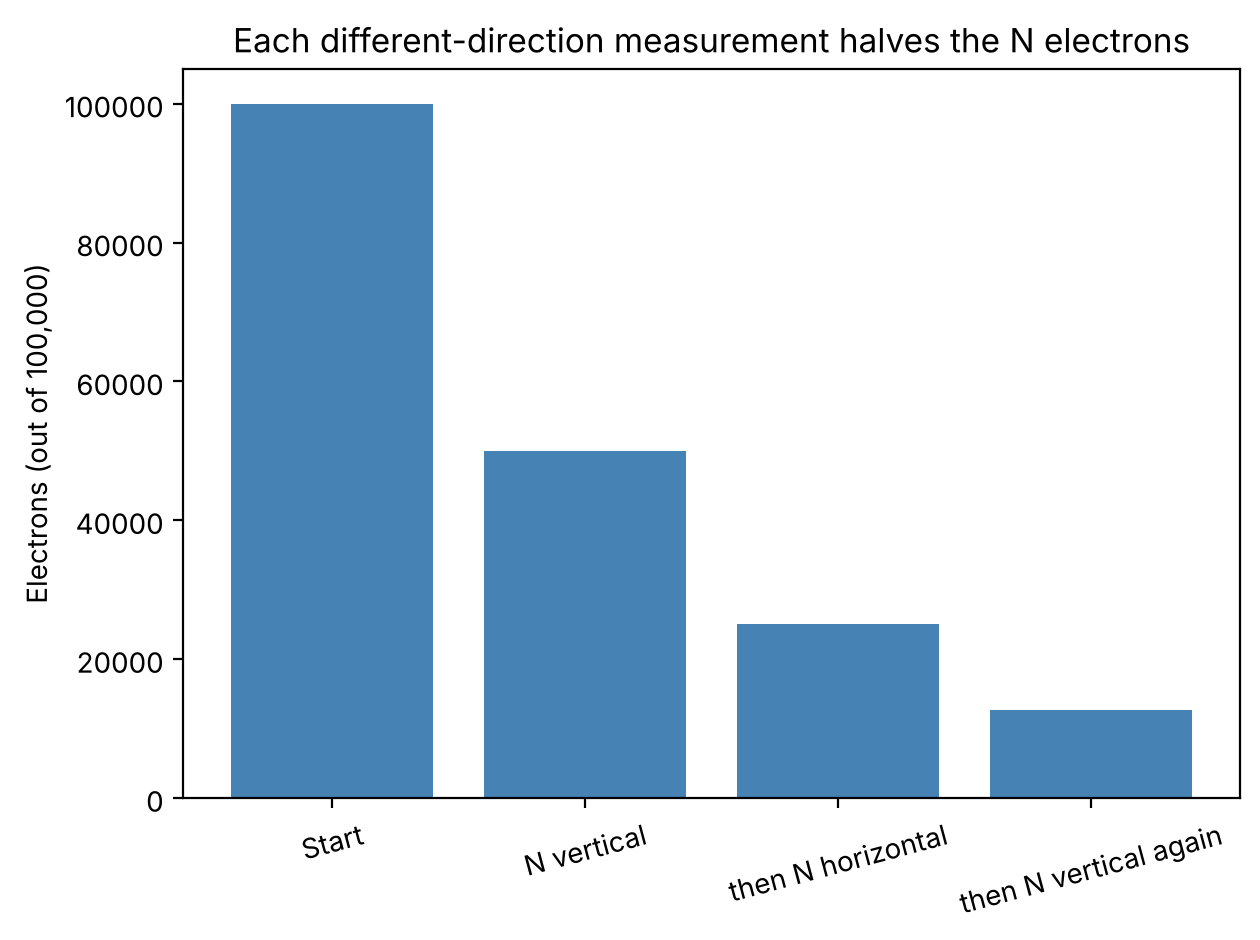

[100000, 49953, 25107, 12647]


In [5]:
random.seed(4)
n = 100_000
start = n
after_v = after_h = after_v2 = 0

for _ in range(n):
    e = Electron()
    if e.measure(VERTICAL) != 'N':
        continue
    after_v += 1
    if e.measure(HORIZONTAL) != 'N':
        continue
    after_h += 1
    if e.measure(VERTICAL) == 'N':
        after_v2 += 1

labels = ['Start', 'N vertical', 'then N horizontal', 'then N vertical again']
values = [start, after_v, after_h, after_v2]
plt.bar(labels, values, color='steelblue')
plt.ylabel('Electrons (out of 100,000)')
plt.title('Each different-direction measurement halves the N electrons')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print(values)

## 6. Quantum randomness vs a coin toss

The book says a coin toss only *looks* random, while quantum randomness is believed to be real. In code both use `random.choice`, so this simulation cannot show that difference. A computer's random numbers are also only pseudorandom.

The real test of "true randomness" is Bell's inequality in chapter 5.

## 7. Spin results as bits

The chapter ends by saying the final answer of a quantum computation is classical bits. I can map N to 0 and S to 1.

In [6]:
random.seed(5)
bits = []
for _ in range(16):
    e = Electron()
    e.measure(VERTICAL)
    result = e.measure(HORIZONTAL)
    bits.append(0 if result == 'N' else 1)

print(''.join(map(str, bits)))

1100110011010000


## What I learned

- Repeating a measurement is predictable. Changing the direction makes the result random.
- Measuring along a new direction wipes out the earlier answer, which is why vertical, horizontal, vertical ends at 50/50.
- The simulation reproduces the book's results, but it only follows the rules. The mathematical reason comes in chapters 2 and 3.

**Next:** chapter 2 (linear algebra).